# 16 — Dónde está el problema: concentración y qué explica la duración
Sobre el estrato de **procesos no penales** (1.655 filas, la capa curada de los notebooks 10 a 12), dos preguntas que el EDA
dejó abiertas:

1. **¿Qué tan concentrado está el rezago?** Si unas pocas celdas explican casi todo, la priorización es distinta a si se reparte parejo.
2. **¿Qué explica la duración estimada?** La hipótesis del proyecto es que la demora no es homogénea y que importa más *qué tipo de caso*
   es que *dónde* se tramita. Aquí se mide con una descomposición de varianza: cuánto de la variación de la duración queda
   explicado por el ámbito, el departamento, la materia y el tipo de proceso.

No se ajusta ningún modelo predictivo: es descripción. Solo **agrega** archivos nuevos en `data/curated/eda/`.

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/flujo.ipynb
import numpy as np
import matplotlib.pyplot as plt

OUT_EDA = CURATED / "eda"
OUT_EDA.mkdir(parents=True, exist_ok=True)

curado = pd.read_parquet(CURATED / "features" / "dataset_analitico_curado.parquet")
proc = curado[curado["tipo_elemento_analitico"] == "proceso"].copy()
assert len(proc) == 1655
print(len(proc), "procesos;", int(proc["duracion_estimada_dias"].notna().sum()), "con duración estimada (tienen causas resueltas)")

1655 procesos; 1122 con duración estimada (tienen causas resueltas)


## Concentración del rezago
`pendientes_fin` ordenado de mayor a menor: qué parte del stock está en las primeras filas, en los primeros tipos de proceso y en los primeros departamentos.

In [2]:
pend = proc["pendientes_fin"].astype(float)
orden = pend.sort_values(ascending=False).reset_index(drop=True)
total = float(orden.sum())
sin_pendientes = int((pend == 0).sum())
filas = []
for k in [10, 25, 50, 100, 165]:
    filas.append({"nivel": "filas con más pendientes", "categoria": "las " + str(k) + " primeras de 1.655 (" + "{:.1f}".format(k / len(proc) * 100).replace(".", ",") + " %)",
                  "pendientes": float(orden.head(k).sum()), "pct_del_rezago": float(orden.head(k).sum() / total * 100)})
por_tipo = proc.groupby("tipo_proceso")["pendientes_fin"].sum().sort_values(ascending=False)
por_depto = proc.groupby("departamento_derivado")["pendientes_fin"].sum().sort_values(ascending=False)
por_materia = proc.groupby("materia_homologada")["pendientes_fin"].sum().sort_values(ascending=False)
for nombre, serie_ in [("tipo de proceso", por_tipo), ("departamento", por_depto), ("materia", por_materia)]:
    for categoria, valor in serie_.items():
        filas.append({"nivel": nombre, "categoria": categoria, "pendientes": float(valor), "pct_del_rezago": float(valor / total * 100)})
conc = pd.DataFrame(filas)
conc.to_csv(OUT_EDA / "concentracion_rezago.csv", index=False, encoding="utf-8")

print("{} de {} procesos no tienen causas pendientes".format(sin_pendientes, len(proc)))
for k in [10, 100, 165]:
    print("las {} filas con más pendientes concentran el {:.1f} % del rezago".format(k, orden.head(k).sum() / total * 100))
print("los 10 tipos de proceso con más pendientes: {:.1f} % de {} tipos".format(por_tipo.head(10).sum() / total * 100, len(por_tipo)))
print("los 2 departamentos con más pendientes ({}): {:.1f} %".format(" y ".join(por_depto.index[:2]), por_depto.head(2).sum() / total * 100))
conc[conc["nivel"].isin(["tipo de proceso"])].head(10).round(1)

566 de 1655 procesos no tienen causas pendientes
las 10 filas con más pendientes concentran el 22.1 % del rezago
las 100 filas con más pendientes concentran el 73.4 % del rezago
las 165 filas con más pendientes concentran el 84.1 % del rezago
los 10 tipos de proceso con más pendientes: 65.7 % de 87 tipos
los 2 departamentos con más pendientes (La Paz y Santa Cruz): 66.6 %


,nivel,categoria,pendientes,pct_del_rezago
5,tipo de proceso,ASISTENCIA FAMILIAR,18300.0,14.5
6,tipo de proceso,ORDINARIO,13780.0,10.9
7,tipo de proceso,INFRACCION A LEYES SOCIALES,11880.0,9.4
8,tipo de proceso,DIVORCIO -DESVINCULACION Art. 207,8695.0,6.9
9,tipo de proceso,EJECUTIVO,6437.0,5.1
10,tipo de proceso,COACTIVO FISCAL,5961.0,4.7
11,tipo de proceso,COACTIVO SOCIAL AFPs,4696.0,3.7
12,tipo de proceso,"INSCRIPCIÓN, MODIFICACIÓN, CANCELACIÓN O FUSIÓ...",4514.0,3.6
13,tipo de proceso,OTROS VOLUNTARIOS,4330.0,3.4
14,tipo de proceso,ASISTENCIA FAMILIAR CUANDO EXISTA ACUERDO (HOM...,4224.0,3.4


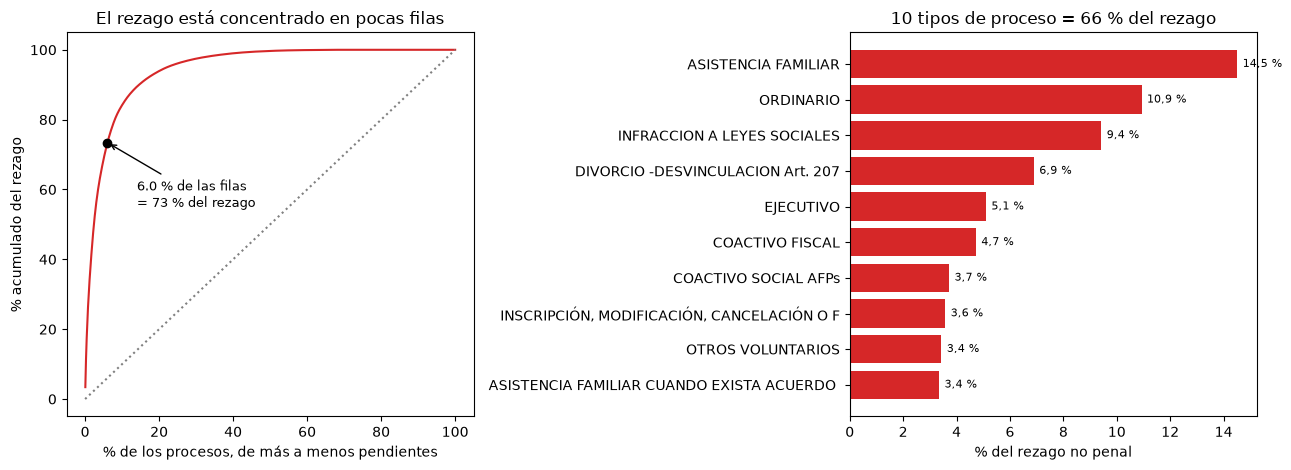

In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(1, len(orden) + 1) / len(orden) * 100
ejes[0].plot(x, orden.cumsum() / total * 100, color="tab:red")
k100 = 100
ejes[0].scatter([k100 / len(orden) * 100], [orden.head(k100).sum() / total * 100], color="black", zorder=3)
ejes[0].annotate("{:.1f} % de las filas\n= {:.0f} % del rezago".format(k100 / len(orden) * 100, orden.head(k100).sum() / total * 100),
                 (k100 / len(orden) * 100, orden.head(k100).sum() / total * 100), xytext=(14, 55), arrowprops={"arrowstyle": "->"}, fontsize=9)
ejes[0].plot([0, 100], [0, 100], color="gray", linestyle=":")
ejes[0].set_xlabel("% de los procesos, de más a menos pendientes")
ejes[0].set_ylabel("% acumulado del rezago")
ejes[0].set_title("El rezago está concentrado en pocas filas")
top = por_tipo.head(10).iloc[::-1] / total * 100
ejes[1].barh([t[:42] for t in top.index], top.values, color="tab:red")
for b, v in zip(ejes[1].patches, top.values):
    ejes[1].text(v + 0.2, b.get_y() + b.get_height() / 2, "{:.1f} %".format(v).replace(".", ","), va="center", fontsize=8)
ejes[1].set_title("10 tipos de proceso = {:.0f} % del rezago".format(por_tipo.head(10).sum() / total * 100))
ejes[1].set_xlabel("% del rezago no penal")
plt.tight_layout()
plt.show()

## Qué explica la duración
Se ajusta `log(1 + duración estimada)` contra variables categóricas y se mide el **R²**: la parte de la variación que cada
factor (o combinación) explica. Tres lecturas:

- **sin pesos**: cada proceso cuenta igual (R² ajustado por el número de categorías);
- **ponderado por `atendidas`** o por **`pendientes_fin`**: cada proceso pesa lo que pesa su volumen, que es lo que importa
  para la duración del sistema (ponderado también ajustado).

Un R² alto describe asociación, no causa, y las categorías con pocas filas lo inflan: por eso se reporta el ajustado.

In [4]:
d = proc[proc["duracion_estimada_dias"].notna()].copy()
d["y"] = np.log1p(d["duracion_estimada_dias"].astype(float))


def r2(df, columnas, peso=None):
    X = pd.get_dummies(df[columnas].astype(str), drop_first=True).astype(float)
    X.insert(0, "c", 1.0)
    y = df["y"].to_numpy(dtype=float)
    w = np.ones(len(df)) if peso is None else df[peso].to_numpy(dtype=float)
    raiz = np.sqrt(w)
    b, *_ = np.linalg.lstsq(X.to_numpy() * raiz[:, None], y * raiz, rcond=None)
    media = np.average(y, weights=w)
    ss_tot = (w * (y - media) ** 2).sum()
    ss_res = (w * (y - X.to_numpy() @ b) ** 2).sum()
    n, k = X.shape
    bruto = 1 - ss_res / ss_tot
    return bruto, 1 - (1 - bruto) * (n - 1) / (n - k), n, k - 1


ESPECIFICACIONES = [
    ("ámbito (capital / provincia)", ["ambito"]),
    ("departamento", ["departamento_derivado"]),
    ("materia", ["materia_homologada"]),
    ("tipo de proceso", ["tipo_proceso"]),
    ("materia + departamento", ["materia_homologada", "departamento_derivado"]),
    ("materia + tipo de proceso + departamento", ["materia_homologada", "tipo_proceso", "departamento_derivado"]),
]
filas = []
for nombre, columnas in ESPECIFICACIONES:
    sin_peso = r2(d, columnas)
    p_at = r2(d[d["atendidas"] > 0], columnas, "atendidas")
    p_pe = r2(d[d["pendientes_fin"] > 0], columnas, "pendientes_fin")
    filas.append({"factor": nombre, "n_sin_pesos": sin_peso[2], "categorias": sin_peso[3],
                  "r2_ajustado_sin_pesos": sin_peso[1], "r2_ajustado_pond_atendidas": p_at[1], "r2_ajustado_pond_pendientes": p_pe[1]})
desc = pd.DataFrame(filas)
desc.to_csv(OUT_EDA / "descomposicion_varianza_duracion.csv", index=False, encoding="utf-8")

fila = desc.set_index("factor")
for col in ["r2_ajustado_sin_pesos", "r2_ajustado_pond_atendidas", "r2_ajustado_pond_pendientes"]:
    assert fila.loc["ámbito (capital / provincia)", col] < 0.02, "el ámbito no debería explicar la duración"
    assert fila.loc["tipo de proceso", col] > fila.loc["materia", col], "el tipo de proceso explica más que la materia"
    assert fila.loc["tipo de proceso", col] > fila.loc["departamento", col]
print("ámbito < 2 %, y el tipo de proceso explica más que la materia y que el departamento, con las tres lecturas")
(desc.set_index("factor")[["categorias", "r2_ajustado_sin_pesos", "r2_ajustado_pond_atendidas", "r2_ajustado_pond_pendientes"]] * [1, 100, 100, 100]).round(1)

ámbito < 2 %, y el tipo de proceso explica más que la materia y que el departamento, con las tres lecturas


,categorias,r2_ajustado_sin_pesos,r2_ajustado_pond_atendidas,r2_ajustado_pond_pendientes
factor,,,,
ámbito (capital / provincia),1,0.0,0.3,0.7
departamento,8,9.7,13.2,14.1
materia,4,5.0,19.2,38.8
tipo de proceso,85,21.0,49.1,56.9
materia + departamento,12,14.7,28.2,45.9
materia + tipo de proceso + departamento,97,31.6,58.6,64.8


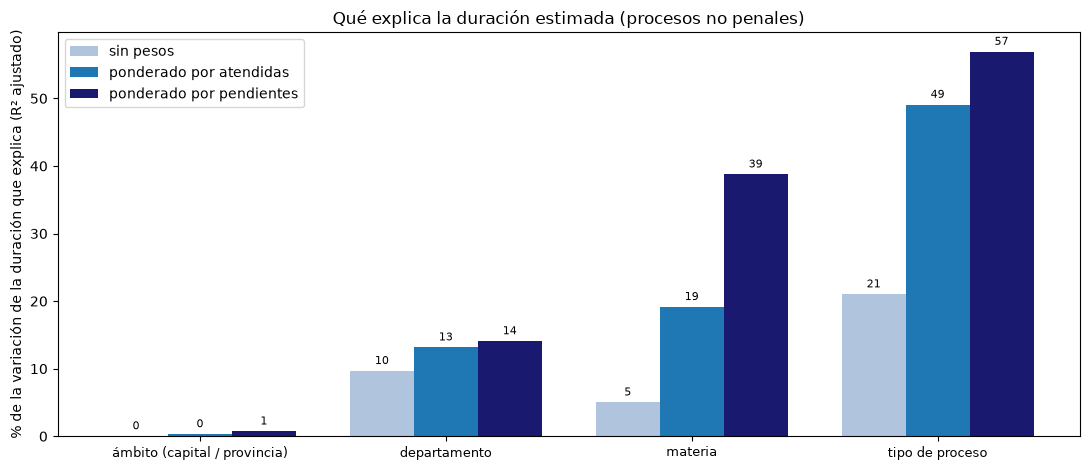

In [5]:
simples = desc.iloc[:4].set_index("factor")
fig, ax = plt.subplots(figsize=(11, 4.8))
ancho = 0.26
posiciones = np.arange(len(simples))
for i, (col, etiqueta, color) in enumerate([("r2_ajustado_sin_pesos", "sin pesos", "lightsteelblue"),
                                           ("r2_ajustado_pond_atendidas", "ponderado por atendidas", "tab:blue"),
                                           ("r2_ajustado_pond_pendientes", "ponderado por pendientes", "midnightblue")]):
    barras = ax.bar(posiciones + (i - 1) * ancho, simples[col] * 100, ancho, label=etiqueta, color=color)
    for b, v in zip(barras, simples[col] * 100):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, "{:.0f}".format(max(v, 0)), ha="center", fontsize=8)
ax.set_xticks(posiciones)
ax.set_xticklabels(simples.index, fontsize=9)
ax.set_ylabel("% de la variación de la duración que explica (R² ajustado)")
ax.set_title("Qué explica la duración estimada (procesos no penales)")
ax.legend()
plt.tight_layout()
plt.show()

## Una prueba que no se adoptó: agrupamiento de procesos
La ruta del proyecto sugería un agrupamiento (K-Means) de los procesos. Antes de adoptarlo se mide si los datos tienen estructura de
grupos con el índice de silhouette (−1 a 1; cerca de 0,5 o más hay grupos claros). Variables estandarizadas: volumen
(`log(1 + atendidas)`), tasa de resolución (cortada en 3), duración (`log(1 + días)`) y tasa de pendencia. K-Means de `scipy`, 5 inicios por *k*, semilla fija.
Es una **prueba de estructura**, no un modelo para publicar: si el silhouette es bajo, el agrupamiento no aporta segmentos naturales.

In [6]:
from scipy.cluster.vq import kmeans2

q = proc[proc["duracion_estimada_dias"].notna() & proc["tasa_resolucion"].notna()].copy()
F = pd.DataFrame({"volumen": np.log1p(q["atendidas"].astype(float)), "tasa_resolucion": q["tasa_resolucion"].astype(float).clip(upper=3),
                  "duracion": np.log1p(q["duracion_estimada_dias"].astype(float)), "pendencia": q["tasa_pendencia"].astype(float)})
Z = ((F - F.mean()) / F.std()).to_numpy(dtype=float)
D = np.sqrt(((Z[:, None, :] - Z[None, :, :]) ** 2).sum(-1))


def silhouette(etiquetas):
    valores = np.zeros(len(Z))
    for i in range(len(Z)):
        propios = etiquetas == etiquetas[i]
        propios[i] = False
        if propios.sum() == 0:
            continue
        a = D[i, propios].mean()
        b = min(D[i, etiquetas == k].mean() for k in set(etiquetas) if k != etiquetas[i])
        valores[i] = (b - a) / max(a, b)
    return valores.mean()


rng = np.random.default_rng(42)
filas = []
for k in range(2, 8):
    mejor = None
    for _ in range(5):
        _, etiquetas = kmeans2(Z, k, minit="++", seed=int(rng.integers(1_000_000)))
        if len(set(etiquetas)) < k:
            continue
        s = silhouette(etiquetas)
        if mejor is None or s > mejor[0]:
            mejor = (s, np.bincount(etiquetas).tolist())
    filas.append({"k": k, "silhouette": round(float(mejor[0]), 3), "tamanos": " / ".join(str(x) for x in sorted(mejor[1], reverse=True))})
agr = pd.DataFrame(filas)
agr.insert(0, "n", len(Z))
agr.to_csv(OUT_EDA / "agrupamiento_prueba.csv", index=False, encoding="utf-8")
assert agr["silhouette"].max() < 0.5, "hay estructura de grupos clara: reconsiderar el agrupamiento"
print("n =", len(Z), "| mejor silhouette: {:.3f} con k = {}".format(agr["silhouette"].max(), int(agr.loc[agr["silhouette"].idxmax(), "k"])),
      "→ no hay grupos naturales claros (< 0,5)")
agr

n = 1082 | mejor silhouette: 0.425 con k = 3 → no hay grupos naturales claros (< 0,5)


,n,k,silhouette,tamanos
0,1082,2,0.375,816 / 266
1,1082,3,0.425,850 / 161 / 71
2,1082,4,0.355,503 / 382 / 131 / 66
3,1082,5,0.351,503 / 380 / 127 / 53 / 19
4,1082,6,0.338,315 / 313 / 239 / 127 / 52 / 36
5,1082,7,0.331,295 / 228 / 191 / 163 / 127 / 43 / 35


## Lectura
- El **ámbito** (capital o provincia), que es la comparación que más se muestra, **no explica nada** de la duración.
- El **departamento** explica algo (del orden de 10 % al 15 %).
- Lo que más explica es el **tipo de proceso**, más que la materia: la hipótesis del proyecto se sostiene y se afina, porque la unidad
  que importa es más fina que la materia.
- Aun combinando los tres factores queda sin explicar una parte (alrededor de dos tercios sin pesos), sobre todo por filas pequeñas con duraciones muy variables.
  Las lecturas ponderadas, que pesan por volumen, explican bastante más.